# Visual sanity check: module definition vs coupling matrices

The `module_specificity_analysis.ipynb` result (essentially no individual
cell survives FDR correction for module-specific coupling) is surprising
given the population-level effect is real. This notebook is a direct visual
gut-check, side by side for each session:

1. **HDBSCAN feature space** (grid spacing vs orientation) — how the modules
   were originally defined
2. **Rate-map UMAP** (OF1 spatial tuning curves, shift-corrected) — an
   independent view of whether the same grouping shows up in tuning shape
3. **Raw pR² matrix** (baseline='null', "cell only")
4. **Δ pR² matrix** (behaviour-controlled coupling)

Matrices 3-4 are ordered identically: Module 0 GC → Module 1 GC → ...
→ unassigned GC → non-grid-spatial (NGS) → other (NS), so any block
structure lines up visually with the module colour used in panels 1-2.

**Note on module numbering**: `HDBSCAN_grid_modules` sorts its OUTPUT list by
ascending mean spacing, but the raw integer tags inside that list are not
guaranteed to be `[0, 1, 2, ...]` in order — a fresh run here found modules
tagged `[1, 0]` for two sessions (list *position* 0, the smallest-spacing
module, was internally tagged "1"). Verified by cluster_id set overlap that
this fresh run reproduces the `cell_classifications.csv` module membership
used in the previous two notebooks exactly (100% overlap once matched by
spacing rank, not raw tag). Everything below uses **list position** as the
module number (position 0 = smallest spacing), never the raw tag, to avoid
this trap.

In [1]:
import numpy as np
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from spatial_manifolds.detect_grids import classify_cells_both_sessions, HDBSCAN_grid_modules, plot_grid_modules_umap

%load_ext autoreload
%autoreload 2
%matplotlib inline
plt.rcParams['font.family'] = 'Arial'

SOURCE_PATH = '/Users/harryclark/Downloads/COHORT12/'
DATA_PATH   = '/Users/harryclark/Documents/spatial-manifolds/data/eddie/xgboost_pairwise/'
FIG_PATH    = '/Users/harryclark/Documents/spatial-manifolds/scripts/figures/figure_playground/module_visual_check/'
os.makedirs(FIG_PATH, exist_ok=True)

HISTORY_LENGTH = 100
RICH_BASELINE  = {'VR': 'pos_speed_lfp', 'OF1': 'pos_speed_hd_hing_lfp'}
RAW_BASELINE   = 'null'

SESSIONS = [
    dict(mouse=26, day=19, sessions=['VR', 'OF1']),
    dict(mouse=25, day=25, sessions=['OF1']),
    dict(mouse=21, day=26, sessions=['OF1']),
]

TAB10 = plt.cm.tab10.colors
FIXED_COLORS = {
    'GC (unassigned)':  '#8e44ad',
    'Non-grid spatial': '#27ae60',
    'Other':             '#7f8c8d',
}

## 1. Per-(mouse, day) setup: fresh HDBSCAN modules + UMAP embedding (computed once, reused across session types)

In [2]:
def load_pairwise(mouse, day, session_type):
    pattern = os.path.join(DATA_PATH, f'xgboost_pairwise_M{mouse}_D{day}_h{HISTORY_LENGTH}_{session_type}_*.csv')
    files = sorted(glob.glob(pattern))
    if not files:
        return None
    return pd.concat([pd.read_csv(f, keep_default_na=False) for f in files], ignore_index=True)


def build_pr2_matrix(pw_df, baseline):
    bl = (pw_df[(pw_df.baseline == baseline) & (pw_df.covariate_cluster_id == -1)]
          [['target_cluster_id', 'pR2_cv']].rename(columns={'pR2_cv': 'pR2_baseline'})
          .drop_duplicates('target_cluster_id'))
    cv = (pw_df[(pw_df.baseline == baseline) & (pw_df.covariate_cluster_id >= 0)]
          [['target_cluster_id', 'covariate_cluster_id', 'pR2_cv']].copy())
    merged = cv.merge(bl, on='target_cluster_id', how='inner')
    merged['d'] = merged['pR2_cv'] - merged['pR2_baseline']
    all_ids = sorted(set(merged.target_cluster_id) | set(merged.covariate_cluster_id))
    idx = {cid: i for i, cid in enumerate(all_ids)}
    N = len(all_ids)
    mat = np.full((N, N), np.nan)
    for row in merged.itertuples(index=False):
        mat[idx[int(row.covariate_cluster_id)], idx[int(row.target_cluster_id)]] = row.d
    np.fill_diagonal(mat, 0)
    sym = np.nan_to_num(np.nanmean(np.stack([mat, mat.T]), axis=0), nan=0.0)
    return sym, all_ids


def setup_session(mouse, day):
    gcs, ngs, allc = classify_cells_both_sessions(mouse, day, percentile_threshold=95,
                                                   source_path=SOURCE_PATH, verbose=False)
    g_m_ids, g_m_cluster_ids, _ = HDBSCAN_grid_modules(
        gcs, allc, mouse, day, min_cluster_size=3, cluster_selection_epsilon=3,
        figpath='', curate_with_vr=True, curate_with_brain_region=True,
        source_path=SOURCE_PATH, verbose=False, ax=None, show=False,
    )
    n_modules = len(g_m_cluster_ids)
    print(f'M{mouse} D{day}: {n_modules} modules, sizes={[len(m) for m in g_m_cluster_ids]}, '
          f'gc={len(gcs)}, ngs={len(ngs)}, all={len(allc)}')

    embedding, umap_cluster_ids = None, None
    if n_modules > 0:
        embedding, _umap_labels, umap_cluster_ids = plot_grid_modules_umap(
            gcs, g_m_ids, g_m_cluster_ids, mouse, day,
            figpath='', source_path=SOURCE_PATH, session='OF1',
            ax=None, show=False, verbose=False,
        )
    return dict(gcs=gcs, ngs=ngs, allc=allc, g_m_cluster_ids=g_m_cluster_ids,
               embedding=embedding, umap_cluster_ids=umap_cluster_ids)


session_setup = {}
for cfg in SESSIONS:
    key = (cfg['mouse'], cfg['day'])
    session_setup[key] = setup_session(*key)

M26 D19: 2 modules, sizes=[38, 3], gc=47, ngs=213, all=280


M25 D25: 2 modules, sizes=[35, 7], gc=44, ngs=49, all=108


M21 D26: 2 modules, sizes=[8, 20], gc=32, ngs=107, all=147


## 2. Grouping / colour helper (consistent across all four panels)

In [3]:
def make_group_lookup(setup):
    gcs_ids = set(setup['gcs']['cluster_id'])
    ngs_ids = set(setup['ngs']['cluster_id'])
    g_m_cluster_ids = setup['g_m_cluster_ids']
    n_modules = len(g_m_cluster_ids)
    module_of = {}
    for pos, ids in enumerate(g_m_cluster_ids):
        for cid in ids:
            module_of[cid] = pos

    def group_of(cid):
        if cid in module_of:
            return f'Module {module_of[cid]} (GC)'
        if cid in gcs_ids:
            return 'GC (unassigned)'
        if cid in ngs_ids:
            return 'Non-grid spatial'
        return 'Other'

    group_order = [f'Module {i} (GC)' for i in range(n_modules)] + list(FIXED_COLORS.keys())
    group_colors = {f'Module {i} (GC)': TAB10[i % len(TAB10)] for i in range(n_modules)}
    group_colors.update(FIXED_COLORS)
    return group_of, group_order, group_colors

## 3. Combined 4-panel figure per session

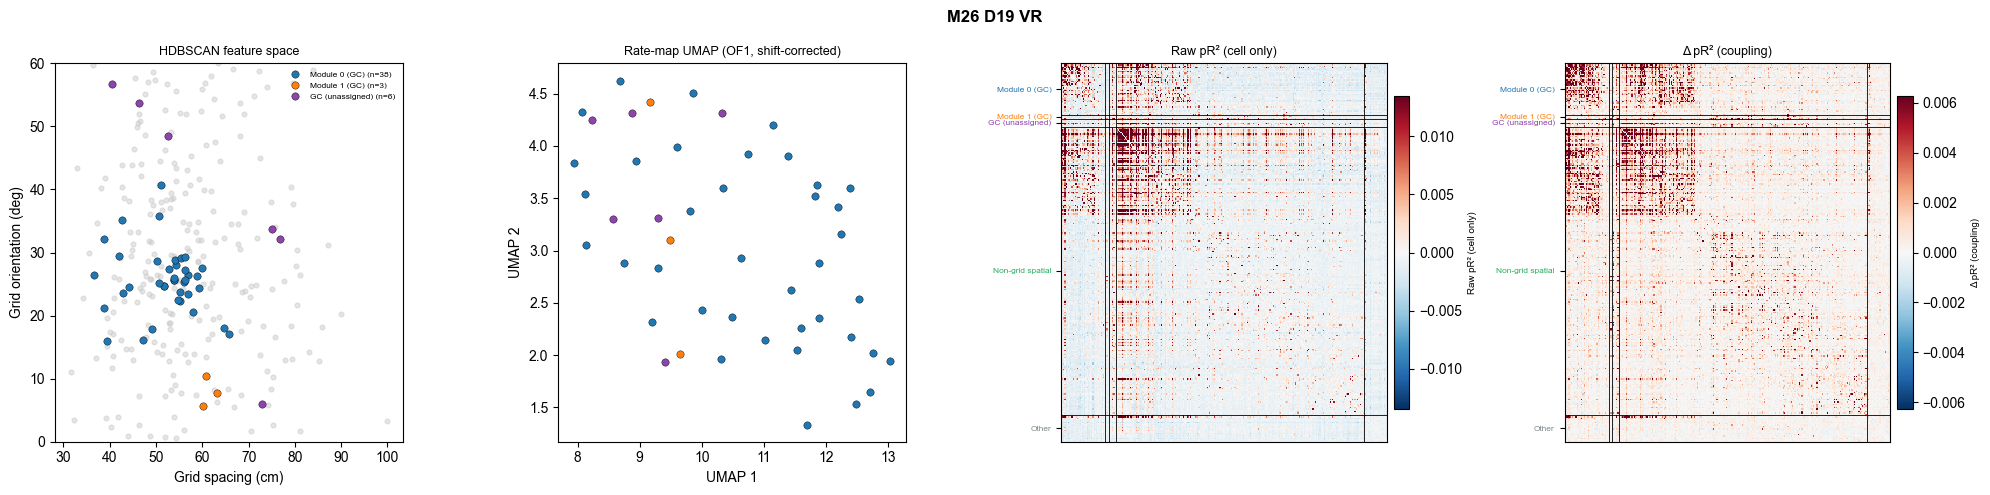

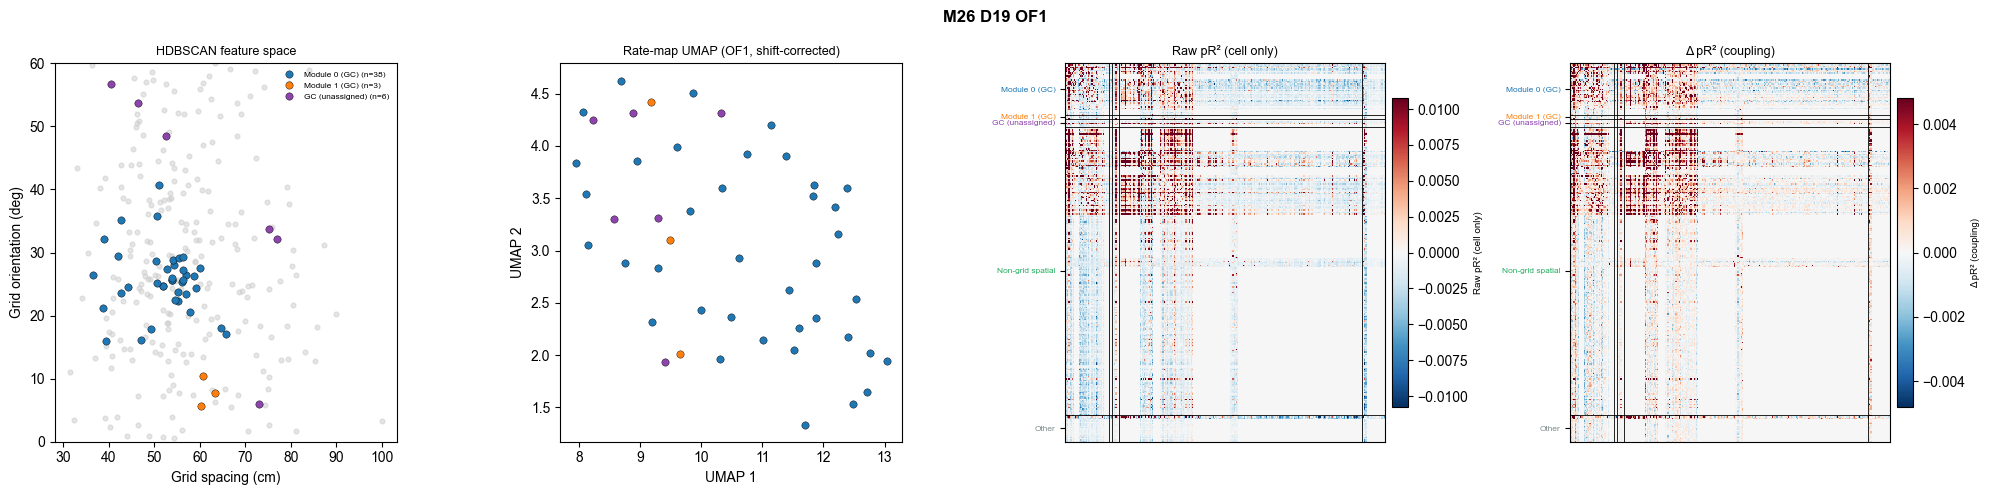

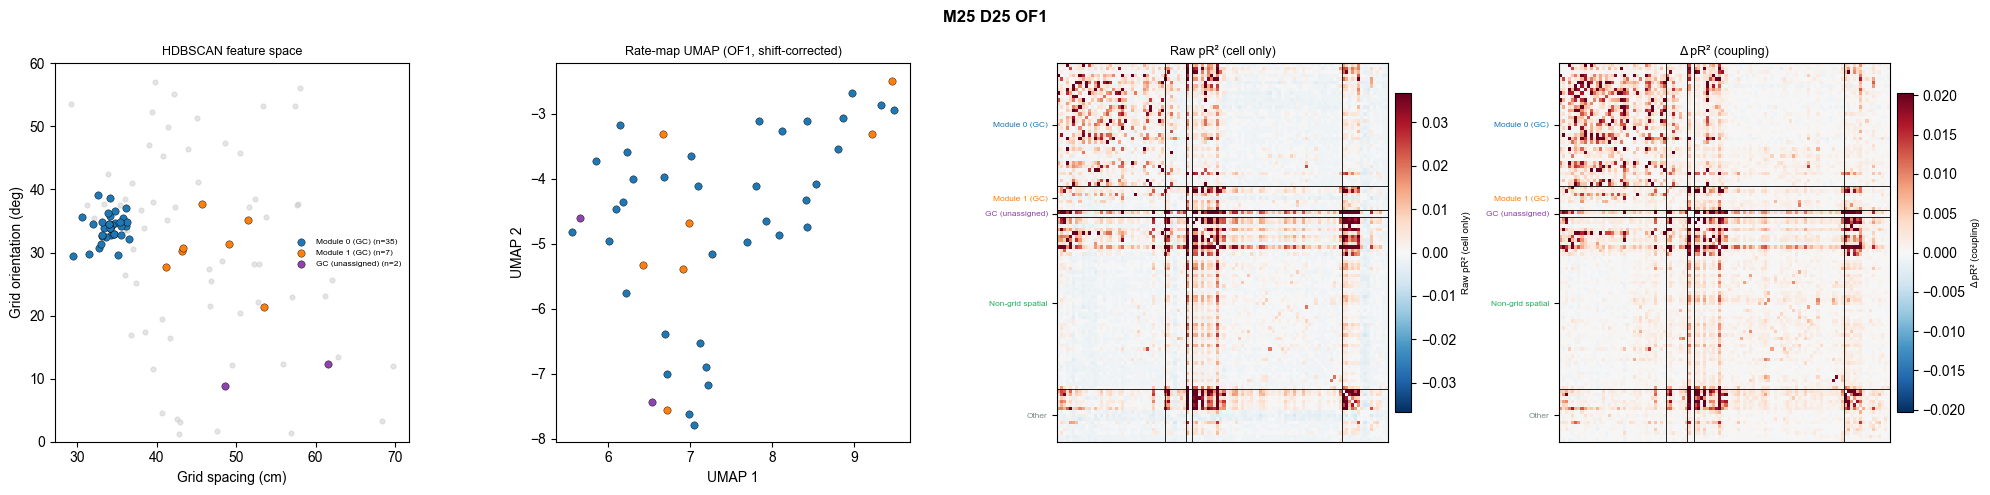

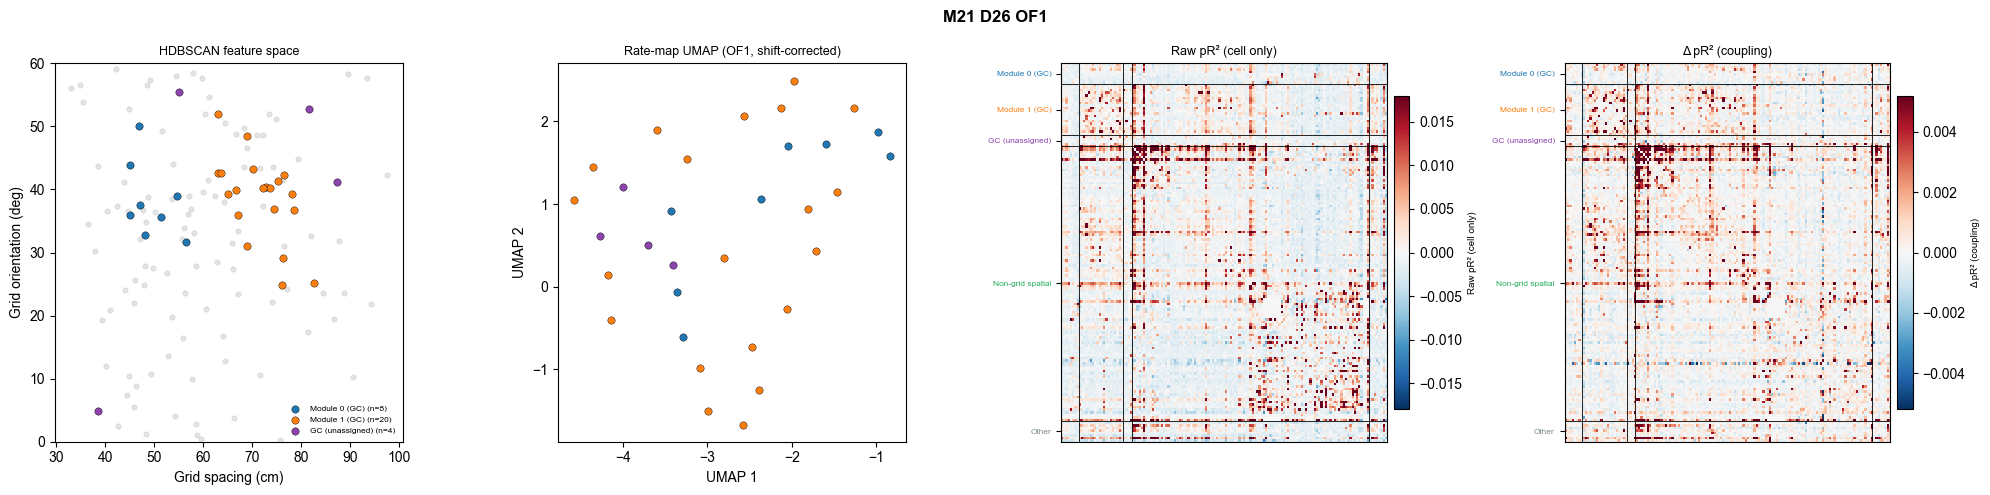

In [4]:
def plot_combined(mouse, day, session_type):
    setup = session_setup[(mouse, day)]
    group_of, group_order, group_colors = make_group_lookup(setup)
    gc_group_order = [g for g in group_order if g.startswith('Module') or g == 'GC (unassigned)']

    pw = load_pairwise(mouse, day, session_type)
    if pw is None:
        print(f'no pairwise CSVs for M{mouse} D{day} {session_type}')
        return None
    raw_sym, ids = build_pr2_matrix(pw, RAW_BASELINE)
    delta_sym, ids2 = build_pr2_matrix(pw, RICH_BASELINE[session_type])
    assert ids == ids2

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    # Panel 1: spacing vs orientation
    ax = axes[0]
    allc, gcs = setup['allc'], setup['gcs']
    ax.scatter(allc['field_spacing'], allc['orientation'], s=12, color='#cccccc', alpha=0.5, zorder=0)
    for g in gc_group_order:
        sub = gcs[gcs['cluster_id'].apply(group_of) == g]
        if len(sub):
            ax.scatter(sub['field_spacing'], sub['orientation'], s=28, color=group_colors[g],
                      label=f'{g} (n={len(sub)})', edgecolors='k', linewidths=0.3, zorder=2)
    ax.set_xlabel('Grid spacing (cm)'); ax.set_ylabel('Grid orientation (deg)')
    ax.set_ylim(0, 60)
    ax.set_title('HDBSCAN feature space', fontsize=9)
    ax.legend(fontsize=6, frameon=False)

    # Panel 2: UMAP
    ax = axes[1]
    if setup['embedding'] is not None:
        emb, umap_ids = setup['embedding'], setup['umap_cluster_ids']
        groups_umap = np.array([group_of(c) for c in umap_ids])
        for g in gc_group_order:
            m = groups_umap == g
            if m.any():
                ax.scatter(emb[m, 0], emb[m, 1], s=28, color=group_colors[g],
                          edgecolors='k', linewidths=0.3, zorder=2)
    ax.set_xlabel('UMAP 1'); ax.set_ylabel('UMAP 2')
    ax.set_title('Rate-map UMAP (OF1, shift-corrected)', fontsize=9)

    # Panels 3-4: matrices, ordered by group
    groups = [group_of(cid) for cid in ids]
    order = sorted(range(len(ids)), key=lambda i: group_order.index(groups[i]))
    sorted_groups = [groups[i] for i in order]
    bounds = [i for i in range(1, len(sorted_groups)) if sorted_groups[i] != sorted_groups[i - 1]]
    block_starts = [0] + bounds
    block_ends = bounds + [len(sorted_groups)]
    tick_pos = [(s + e) / 2 - 0.5 for s, e in zip(block_starts, block_ends)]
    tick_lab = [sorted_groups[s] for s in block_starts]

    for ax, mat, name in zip([axes[2], axes[3]], [raw_sym, delta_sym],
                              ['Raw pR² (cell only)', 'Δ pR² (coupling)']):
        m = mat[np.ix_(order, order)]
        vmax = np.nanpercentile(np.abs(m), 98) if np.any(m != 0) else 1.0
        im = ax.imshow(m, cmap='RdBu_r', vmin=-vmax, vmax=vmax, interpolation='nearest', aspect='auto')
        plt.colorbar(im, ax=ax, fraction=0.045, pad=0.02).set_label(name, fontsize=7)
        for b in bounds:
            ax.axhline(b - 0.5, color='k', lw=0.6)
            ax.axvline(b - 0.5, color='k', lw=0.6)
        ax.set_title(name, fontsize=9)
        ax.set_xticks([])
        ax.set_yticks(tick_pos)
        ax.set_yticklabels(tick_lab, fontsize=6)
        for lab, gname in zip(ax.get_yticklabels(), tick_lab):
            lab.set_color(group_colors.get(gname, '#333333'))

    fig.suptitle(f'M{mouse} D{day} {session_type}', fontsize=12, fontweight='bold')
    plt.tight_layout()
    return fig


COMBOS = [(26, 19, 'VR'), (26, 19, 'OF1'), (25, 25, 'OF1'), (21, 26, 'OF1')]
for mouse, day, session_type in COMBOS:
    fig = plot_combined(mouse, day, session_type)
    if fig is not None:
        fig.savefig(os.path.join(FIG_PATH, f'combined_M{mouse}D{day}_{session_type}.pdf'),
                   dpi=200, bbox_inches='tight')
        plt.show()